In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
import torch
import pandas as pd
from timesfm3 import TimesFM3Forecaster

In [2]:
# Set random seeds for reproducibility
np.random.seed(42)
torch.manual_seed(42)

print(f"PyTorch version: {torch.__version__}")
print(f"CUDA available: {torch.cuda.is_available()}")

PyTorch version: 2.13.0+cu130
CUDA available: False


In [4]:
# Leitura e pré-processamento SP
df = pd.read_excel('data/Dados Demanda Ciclo Otto 8-3009.xlsx', sheet_name='Demanda Ciclo Otto (ANP)')
df.columns = ['ds', 'EHC', 'y', 'Otto']
df.drop(['EHC', 'Otto'], axis=1, inplace=True)
df["unique_id"] = 'BR'
df.tail()

,ds,y,unique_id
195,2026-04-01,3940074.400,BR
196,2026-05-01,3855061.887,BR
197,2026-06-01,3876406.469,BR
198,2026-07-01,4002461.748,BR
199,2026-08-01,3763551.085,BR


## TimesFM3

In [2]:
MODEL_PATH = "../../TimesFM3"

forecaster = TimesFM3Forecaster.from_pretrained(
    MODEL_PATH,
    per_core_batch_size=4,
    local_files_only=True
)

Loading weights from local directory


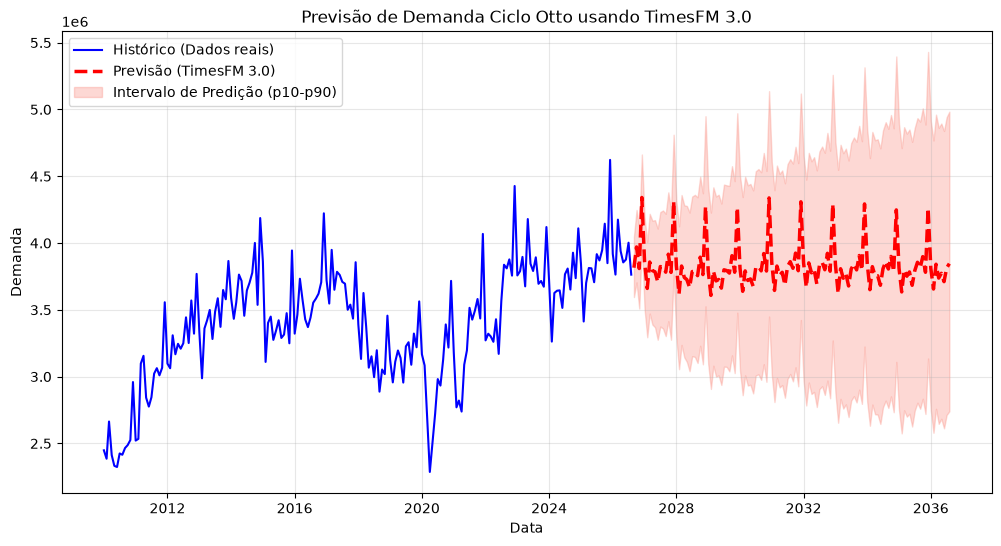

In [10]:
# Preparar os dados
context = df['y'].values.astype(np.float32)
horizon_len = 120

# Gerar a previsão utilizando o TimesFM 3.0
torch_out = forecaster.predict(
    context=context,
    horizon=horizon_len,
    return_quantiles=True
)

# O ponto de previsão central fica em torch_out.forecast
forecast_values = torch_out.forecast

# Gerar as datas futuras correspondentes à previsão (mensal)
last_date = pd.to_datetime(df['ds'].iloc[-1])
forecast_dates = pd.date_range(start=last_date + pd.DateOffset(months=1), periods=horizon_len, freq='MS')

# Plotar histórico e previsão
plt.figure(figsize=(12, 6))
plt.plot(pd.to_datetime(df['ds']), df['y'], label='Histórico (Dados reais)', color='blue')
plt.plot(forecast_dates, forecast_values, label='Previsão (TimesFM 3.0)', color='red', linestyle='--', linewidth=2.5)
if torch_out.quantiles is not None:
    plt.fill_between(
        forecast_dates,
        torch_out.quantiles[:, 0],
        torch_out.quantiles[:, -1],
        color="salmon",
        alpha=0.3,
        label="Intervalo de Predição (p10-p90)"
    )
plt.title('Previsão de Demanda Ciclo Otto usando TimesFM 3.0')
plt.xlabel('Data')
plt.ylabel('Demanda')
plt.legend(loc='upper left')
plt.grid(True, alpha=0.3)
plt.show()

In [7]:
def soma_anual_completa(df_series):
    """Soma os valores mensais por ano apenas se o ano estiver completo (12 meses)."""
    df_temp = df_series.copy()
    df_temp['ano'] = df_temp.index.year
    
    # Filtra apenas anos que possuem 12 meses de dados
    anos_completos = df_temp.groupby('ano').size()
    anos_completos = anos_completos[anos_completos == 12].index
    
    df_filtrado = df_temp[df_temp['ano'].isin(anos_completos)]
    
    # Agrupa por ano e soma
    df_anual = df_filtrado.groupby('ano').sum()
    return df_anual

def completar_primeiro_ano(df_previsto, series_real):
    """
    Para anos de transição onde a previsão começa no meio do ano,
    preenche o restante dos meses anteriores com dados reais para permitir a soma anual.
    """
    primeiro_ano_prev = df_previsto.index.min().year
    meses_previstos = df_previsto[df_previsto.index.year == primeiro_ano_prev]
    
    if len(meses_previstos) < 12:
        # Buscar dados históricos reais do mesmo ano
        real_mesmo_ano = series_real[series_real.index.year == primeiro_ano_prev]
        # Filtrar meses reais que não estão na previsão
        real_complemento = real_mesmo_ano[~real_mesmo_ano.index.month.isin(meses_previstos.index.month)]
        
        # Criar dataframe de complemento com as mesmas colunas da previsão
        complemento_df = pd.DataFrame(index=real_complemento.index)
        for col in df_previsto.columns:
            if col == 'timesfm':
                complemento_df['timesfm'] = real_complemento
            elif col.startswith('q_'):
                # Para os quantis, aproximamos usando os dados reais de histórico do mesmo ano
                complemento_df[col] = real_complemento
        
        df_completo = pd.concat([complemento_df, df_previsto]).sort_index()
        return df_completo
    return df_previsto

def anual_timesfm(df_real, df_prev):
    # Preparar DataFrame real
    real = df_real.copy()
    real['ds'] = pd.to_datetime(real['ds'])
    real = real.set_index("ds")["y"]
    
    historico = soma_anual_completa(real.to_frame()).reset_index()
    historico.rename(columns={'y': 'Historico_Anual', 'ano': 'ds'}, inplace=True)
    
    # Preparar DataFrame previsto
    previsto = df_prev.copy()
    previsto['ds'] = pd.to_datetime(previsto['ds'])
    previsto = previsto.set_index("ds")
    
    # Completar o primeiro ano de previsão com o histórico real correspondente
    previsto_completo = completar_primeiro_ano(previsto, real)
    
    # Agrupar e somar anualmente
    previsto_anual = soma_anual_completa(previsto_completo).reset_index()
    previsto_anual.rename(columns={'ano': 'ds'}, inplace=True)
    
    return historico, previsto_anual

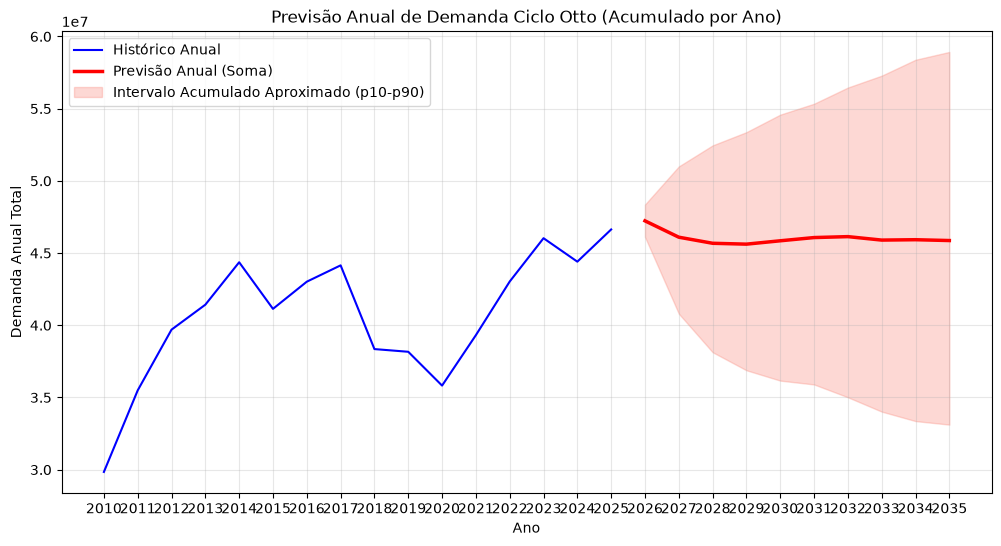

In [8]:
# 1. Estruturar o DataFrame de previsões mensais com os quantis do TimesFM 3.0
quantis_df = pd.DataFrame(torch_out.quantiles, columns=[f'q_{i}' for i in range(torch_out.quantiles.shape[1])])

df_prev_mensal = pd.DataFrame({
    'ds': forecast_dates,
    'timesfm': forecast_values,
})
df_prev_mensal = pd.concat([df_prev_mensal, quantis_df], axis=1)

# 2. Aplicar a anualização
historico_anual, previsto_anual = anual_timesfm(df, df_prev_mensal)

# 3. Plotar o Gráfico Anual
plt.figure(figsize=(12, 6))
plt.plot(historico_anual['ds'], historico_anual['Historico_Anual'], label='Histórico Anual', color='blue')
plt.plot(previsto_anual['ds'], previsto_anual['timesfm'], label='Previsão Anual (Soma)', color='red', linewidth=2.5)

# Adicionar o intervalo de quantis acumulados aproximados (soma dos quantis)
q_col_min = 'q_0'
q_col_max = f'q_{torch_out.quantiles.shape[1]-1}'

if q_col_min in previsto_anual.columns and q_col_max in previsto_anual.columns:
    plt.fill_between(
        previsto_anual['ds'],
        previsto_anual[q_col_min],
        previsto_anual[q_col_max],
        color="salmon",
        alpha=0.3,
        label="Intervalo Acumulado Aproximado (p10-p90)"
    )
plt.title('Previsão Anual de Demanda Ciclo Otto (Acumulado por Ano)')
plt.xlabel('Ano')
plt.ylabel('Demanda Anual Total')
plt.legend(loc='upper left')
plt.grid(True, alpha=0.3)
plt.xticks(pd.concat([historico_anual['ds'], previsto_anual['ds']]).unique())
plt.show()

In [9]:
# Leitura e pré-processamento SP
df_2 = pd.read_excel('data/Dados Demanda Ciclo Otto 8-3009.xlsx', sheet_name='Demanda Ciclo Otto (ANP)')
df_2.columns = ['ds', 'y', 'Gas', 'Otto']
df_2.drop(['Gas', 'Otto'], axis=1, inplace=True)
df_2["unique_id"] = 'BR'
df_2.tail()

,ds,y,unique_id
195,2026-04-01,1841266.997,BR
196,2026-05-01,1799043.964,BR
197,2026-06-01,1831439.047,BR
198,2026-07-01,1919315.052,BR
199,2026-08-01,2018184.481,BR


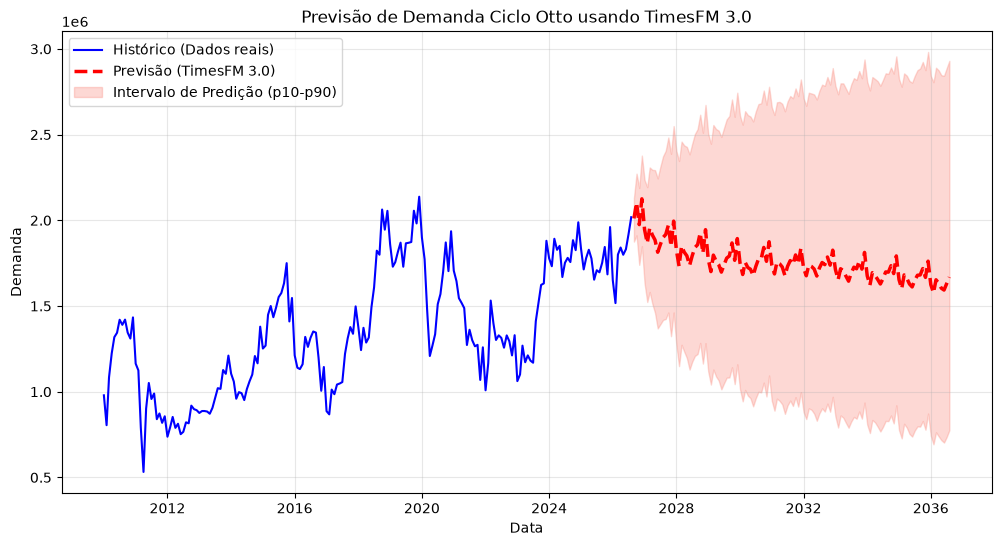

In [12]:
# Preparar os dados
context = df_2['y'].values.astype(np.float32)
horizon_len = 120

# Gerar a previsão utilizando o TimesFM 3.0
torch_out = forecaster.predict(
    context=context,
    horizon=horizon_len,
    return_quantiles=True
)

# O ponto de previsão central (geralmente mediana/p50) fica em torch_out.forecast
forecast_values = torch_out.forecast

# Gerar as datas futuras correspondentes à previsão (mensal)
last_date = pd.to_datetime(df_2['ds'].iloc[-1])
forecast_dates = pd.date_range(start=last_date + pd.DateOffset(months=1), periods=horizon_len, freq='MS')

# Plotar histórico e previsão
plt.figure(figsize=(12, 6))
plt.plot(pd.to_datetime(df_2['ds']), df_2['y'], label='Histórico (Dados reais)', color='blue')
plt.plot(forecast_dates, forecast_values, label='Previsão (TimesFM 3.0)', color='red', linestyle='--', linewidth=2.5)
if torch_out.quantiles is not None:
    plt.fill_between(
        forecast_dates,
        torch_out.quantiles[:, 0],
        torch_out.quantiles[:, -1],
        color="salmon",
        alpha=0.3,
        label="Intervalo de Predição (p10-p90)"
    )
plt.title('Previsão de Demanda Ciclo Otto usando TimesFM 3.0')
plt.xlabel('Data')
plt.ylabel('Demanda')
plt.legend(loc='upper left')
plt.grid(True, alpha=0.3)
plt.show()

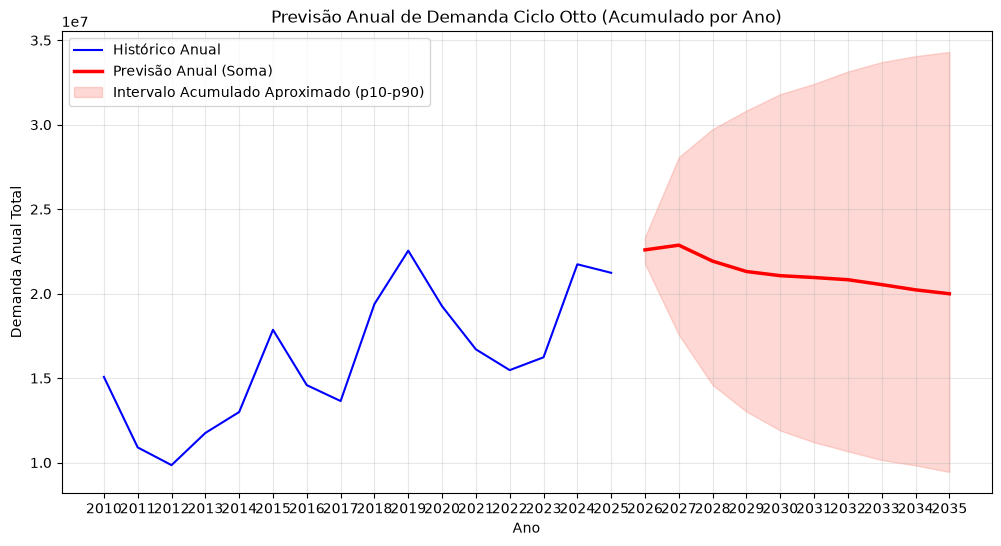

In [13]:
# 1. Estruturar o DataFrame de previsões mensais com os quantis do TimesFM 3.0
quantis_df_2 = pd.DataFrame(torch_out.quantiles, columns=[f'q_{i}' for i in range(torch_out.quantiles.shape[1])])

df_2_prev_mensal = pd.DataFrame({
    'ds': forecast_dates,
    'timesfm': forecast_values,
})
df_2_prev_mensal = pd.concat([df_2_prev_mensal, quantis_df_2], axis=1)

# 2. Aplicar a anualização
historico_anual, previsto_anual = anual_timesfm(df_2, df_2_prev_mensal)

# 3. Plotar o Gráfico Anual
plt.figure(figsize=(12, 6))
plt.plot(historico_anual['ds'], historico_anual['Historico_Anual'], label='Histórico Anual', color='blue')
plt.plot(previsto_anual['ds'], previsto_anual['timesfm'], label='Previsão Anual (Soma)', color='red', linewidth=2.5)

# Adicionar o intervalo de quantis acumulados aproximados (soma dos quantis)
q_col_min = 'q_0'
q_col_max = f'q_{torch_out.quantiles.shape[1]-1}'

if q_col_min in previsto_anual.columns and q_col_max in previsto_anual.columns:
    plt.fill_between(
        previsto_anual['ds'],
        previsto_anual[q_col_min],
        previsto_anual[q_col_max],
        color="salmon",
        alpha=0.3,
        label="Intervalo Acumulado Aproximado (p10-p90)"
    )

plt.title('Previsão Anual de Demanda Ciclo Otto (Acumulado por Ano)')
plt.xlabel('Ano')
plt.ylabel('Demanda Anual Total')
plt.legend(loc='upper left')
plt.grid(True, alpha=0.3)
plt.xticks(pd.concat([historico_anual['ds'], previsto_anual['ds']]).unique())
plt.show()

## Teste AUTOGE

In [16]:
PATH_DATA = "data"
arquivo = 'Dados Demanda Ciclo Otto 8-3009.xlsx'
excel_file = os.path.join(PATH_DATA, arquivo)

In [25]:
print("Processando: Gasolina - TimesFM...")
df_gas = (
    pd.read_excel(excel_file, sheet_name="Demanda Ciclo Otto (ANP)")
      .rename(columns={
          "Unnamed: 0": "Data",
          "Demanda Etanol Hidratado (m3)": "Etanol",
          "Demanda Gasolina C (m3)": "Gasolina",
          "Demanda Ciclo Otto (m3 gasolina equivalente)": "Otto"
      })
      .drop(["Otto", "Etanol"], axis=1)
)
df_gas.columns = ["ds", "y"]
df_gas["unique_id"] = "BR"
df_gas["ds"] = pd.to_datetime(df_gas["ds"])

Processando: Gasolina - TimesFM...


In [33]:
print("Processando: Gasolina - TimesFM...")
df_gas = (
    pd.read_excel(excel_file, sheet_name="Demanda Ciclo Otto (ANP)")
      .rename(columns={
          "Unnamed: 0": "Data",
          "Demanda Etanol Hidratado (m3)": "Etanol",
          "Demanda Gasolina C (m3)": "Gasolina",
          "Demanda Ciclo Otto (m3 gasolina equivalente)": "Otto"
      })
      .drop(["Otto", "Etanol"], axis=1)
)
df_gas.columns = ["ds", "y"]
df_gas["unique_id"] = "BR"
df_gas["ds"] = pd.to_datetime(df_gas["ds"])

ultimo_mes = df_gas["ds"].max().month
meses_faltantes = 12 - ultimo_mes
tam_horizonte = 120 + meses_faltantes

MODEL_PATH_FOUNDATION = "../../TimesFM3"

forecaster = TimesFM3Forecaster.from_pretrained(
    MODEL_PATH_FOUNDATION,
    per_core_batch_size=4,
    local_files_only=True
)

# Preparar os dados
context = df_gas['y'].values.astype(np.float32)

# Gerar a previsão utilizando o TimesFM 3.0
torch_out = forecaster.predict(
    context=context,
    horizon=tam_horizonte,
    return_quantiles=True
)

# O ponto de previsão central fica em torch_out.forecast
forecast_values = torch_out.forecast

# Gerar as datas futuras correspondentes à previsão (mensal)
last_date = pd.to_datetime(df_gas['ds'].iloc[-1])
forecast_dates = pd.date_range(start=last_date + pd.DateOffset(months=1), 
                               periods=horizon_len, freq='MS')

# Usando reset_index() para evitar ambiguidade do "ds" no merge
df_gas_anual_FM = df_gas.drop(columns=["unique_id"]).set_index("ds").resample("YE").sum().reset_index()

serie_df = forecast_values.copy()
serie_df["ds"] = pd.to_datetime(serie_df["ds"])
serie_df_anual = serie_df.drop(columns=["unique_id"]).set_index("ds").resample("YE").sum().reset_index()

# Corrigir o ano de transição (no caso em que esse codigo foi escrito: 2026)
ultimo_ano_hist = df_gas["ds"].dt.year.max()
primeiro_ano_forecast = forecast_values["ds"].dt.year.min()
if ultimo_ano_hist == primeiro_ano_forecast:
    ano_transicao = ultimo_ano_hist
    # Histórico do ano de transição
    hist_parcial = df_gas[
        df_gas["ds"].dt.year == ano_transicao
    ].copy()
    # Forecast do mesmo ano
    forecast_parcial = forecast_values[
        forecast_values["ds"].dt.year == ano_transicao
    ].copy()
    # Soma anual completa
    valor_anual = (
        hist_parcial["y"].sum()
        + forecast_parcial["timesfm"].sum()
    )
    p10_anual = forecast_parcial["timesfm-q-0.1"].sum()
    p90_anual = forecast_parcial["timesfm-q-0.9"].sum()
    data_ano = pd.Timestamp(f"{ano_transicao}-12-31")

    # Atualiza último registro do histórico anual
    mask_hist = df_gas_anual_FM["ds"] == data_ano
    if mask_hist.any():
        df_gas_anual_FM.loc[mask_hist, "y"] = valor_anual

    # Atualiza primeiro registro da previsão anual
    mask_prev = serie_df_anual["ds"] == data_ano
    if mask_prev.any():
        serie_df_anual.loc[mask_prev, "timesfm"] = valor_anual
        serie_df_anual.loc[mask_prev, "timesfm-q-0.1"] = p10_anual
        serie_df_anual.loc[mask_prev, "timesfm-q-0.9"] = p90_anual

# Remover intervalo do primeiro ano previsto (pois o historico não tem intervalo para compeltar
serie_df_anual.loc[
    serie_df_anual.index[0],
    ["timesfm-q-0.1", "timesfm-q-0.9"]
] = np.nan

# Plot 3
plt.figure(figsize=(15, 5))
plt.title("Gasolina - Previsão Anual (TimesFM)")
plt.plot(df_gas_anual_FM["ds"], df_gas_anual_FM["y"], label="Série Original", color="royalblue")
plt.plot(serie_df_anual["ds"], serie_df_anual["timesfm"], label="Previsão TimesFM", color="orange")
plt.fill_between(
    serie_df_anual["ds"],
    serie_df_anual["timesfm-q-0.1"],
    serie_df_anual["timesfm-q-0.9"],
    label="Intervalo de Previsão 80%",
    color="orange",
    alpha=0.3,
)
plt.xlabel("Data")
plt.ylabel("Demanda (m³)")
plt.grid(linestyle="--", color="grey", alpha=0.4)
plt.legend()
plt.tight_layout()
plt.savefig(os.path.join(PATH_PLOTS, "gasolina_timesfm_anual.png"), bbox_inches="tight")
plt.close()

Processando: Gasolina - TimesFM...
Loading weights from local directory


IndexError: only integers, slices (`:`), ellipsis (`...`), numpy.newaxis (`None`) and integer or boolean arrays are valid indices

Processando: Gasolina - TimesFM...
Loading weights from local directory


/tmp/ipykernel_1267500/2068777750.py:117: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '47231266.38500003' has dtype incompatible with float32, please explicitly cast to a compatible dtype first.
  serie_df_anual.loc[mask_prev, "timesfm"] = valor_anual


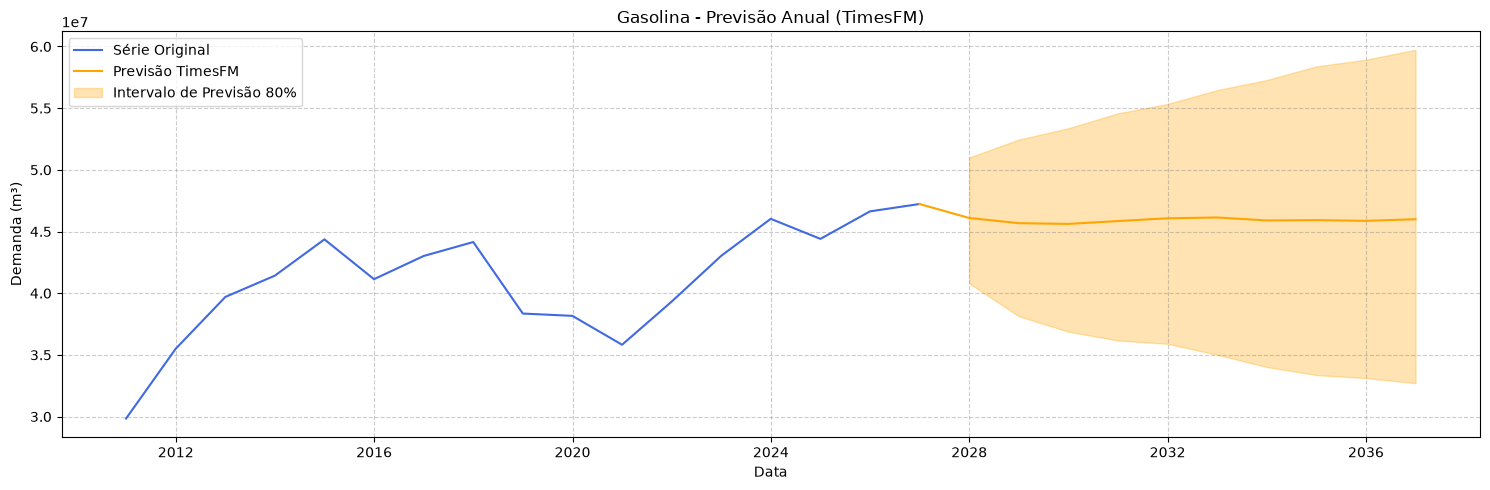

In [34]:
print("Processando: Gasolina - TimesFM...")
df_gas = (
    pd.read_excel(excel_file, sheet_name="Demanda Ciclo Otto (ANP)")
      .rename(columns={
          "Unnamed: 0": "Data",
          "Demanda Etanol Hidratado (m3)": "Etanol",
          "Demanda Gasolina C (m3)": "Gasolina",
          "Demanda Ciclo Otto (m3 gasolina equivalente)": "Otto"
      })
      .drop(["Otto", "Etanol"], axis=1)
)
df_gas.columns = ["ds", "y"]
df_gas["unique_id"] = "BR"
df_gas["ds"] = pd.to_datetime(df_gas["ds"])

ultimo_mes = df_gas["ds"].max().month
meses_faltantes = 12 - ultimo_mes
tam_horizonte = 120 + meses_faltantes

MODEL_PATH_FOUNDATION = "../../TimesFM3"

forecaster = TimesFM3Forecaster.from_pretrained(
    MODEL_PATH_FOUNDATION,
    per_core_batch_size=4,
    local_files_only=True
)

# Preparar os dados
context = df_gas['y'].values.astype(np.float32)
# Gerar a previsão utilizando o TimesFM 3.0
torch_out = forecaster.predict(
    context=context,
    horizon=tam_horizonte,
    return_quantiles=True
)

# ---------------------------------------------------------
# CORREÇÃO: Transformação robusta de Array para DataFrame
# ---------------------------------------------------------
if isinstance(torch_out.forecast, pd.DataFrame):
    forecast_values = torch_out.forecast.copy()
else:
    # Cria o DataFrame explicitamente e nomeia a previsão central
    # como 'timesfm' (como esperado pelo seu código do plot)
    forecast_values = pd.DataFrame({
        "timesfm": np.array(torch_out.forecast).flatten()
    })
    
    # Extrair os quantis caso eles tenham vindo na saída
    if hasattr(torch_out, 'quantiles') and torch_out.quantiles is not None:
        q_array = np.array(torch_out.quantiles)
        
        # Remove dimensão de batch se existir (ex: de (1, horizon, 9) para (horizon, 9))
        if q_array.ndim == 3:
            q_array = q_array[0]
            
        # O TimesFM normalmente retorna 9 quantis (do p10 ao p90).
        if q_array.shape[-1] >= 9:
            forecast_values["timesfm-q-0.1"] = q_array[:, 0]   # Índice 0 = p10
            forecast_values["timesfm-q-0.9"] = q_array[:, -1]  # Último Índice = p90
        else:
            # Fallback
            forecast_values["timesfm-q-0.1"] = forecast_values["timesfm"]
            forecast_values["timesfm-q-0.9"] = forecast_values["timesfm"]
    else:
        # Fallback caso não haja quantis na saída
        forecast_values["timesfm-q-0.1"] = forecast_values["timesfm"]
        forecast_values["timesfm-q-0.9"] = forecast_values["timesfm"]
# ---------------------------------------------------------

# Gerar as datas futuras correspondentes à previsão (mensal)
last_date = pd.to_datetime(df_gas['ds'].iloc[-1])
forecast_dates = pd.date_range(
    start=last_date + pd.DateOffset(months=1),
    periods=tam_horizonte,
    freq='MS'
)

# Agora funciona perfeitamente, pois forecast_values é um DataFrame
forecast_values['ds'] = forecast_dates

# Usando reset_index() para evitar ambiguidade do "ds" no merge
df_gas_anual_FM = df_gas.drop(columns=["unique_id"]).set_index("ds").resample("YE").sum().reset_index()

serie_df = forecast_values.copy()
serie_df["ds"] = pd.to_datetime(serie_df["ds"])

# Remoção segura da coluna unique_id caso ela exista
if "unique_id" in serie_df.columns:
    serie_df = serie_df.drop(columns=["unique_id"])
    
serie_df_anual = serie_df.set_index("ds").resample("YE").sum().reset_index()

# Corrigir o ano de transição
ultimo_ano_hist = df_gas["ds"].dt.year.max()
primeiro_ano_forecast = forecast_values["ds"].dt.year.min()

if ultimo_ano_hist == primeiro_ano_forecast:
    ano_transicao = ultimo_ano_hist
    
    hist_parcial = df_gas[df_gas["ds"].dt.year == ano_transicao].copy()
    forecast_parcial = forecast_values[forecast_values["ds"].dt.year == ano_transicao].copy()
    
    valor_anual = hist_parcial["y"].sum() + forecast_parcial["timesfm"].sum()
    p10_anual = forecast_parcial["timesfm-q-0.1"].sum()
    p90_anual = forecast_parcial["timesfm-q-0.9"].sum()
    data_ano = pd.Timestamp(f"{ano_transicao}-12-31")

    # Atualiza último registro do histórico anual
    mask_hist = df_gas_anual_FM["ds"] == data_ano
    if mask_hist.any():
        df_gas_anual_FM.loc[mask_hist, "y"] = valor_anual

    # Atualiza primeiro registro da previsão anual
    mask_prev = serie_df_anual["ds"] == data_ano
    if mask_prev.any():
        serie_df_anual.loc[mask_prev, "timesfm"] = valor_anual
        serie_df_anual.loc[mask_prev, "timesfm-q-0.1"] = p10_anual
        serie_df_anual.loc[mask_prev, "timesfm-q-0.9"] = p90_anual
        
        # Remover intervalo do primeiro ano previsto 
        serie_df_anual.loc[mask_prev, ["timesfm-q-0.1", "timesfm-q-0.9"]] = np.nan

# Plot
plt.figure(figsize=(15, 5))
plt.title("Gasolina - Previsão Anual (TimesFM)")
plt.plot(df_gas_anual_FM["ds"], df_gas_anual_FM["y"], label="Série Original", color="royalblue")
plt.plot(serie_df_anual["ds"], serie_df_anual["timesfm"], label="Previsão TimesFM", color="orange")
plt.fill_between(
    serie_df_anual["ds"],
    serie_df_anual["timesfm-q-0.1"],
    serie_df_anual["timesfm-q-0.9"],
    label="Intervalo de Previsão 80%",
    color="orange",
    alpha=0.3,
)
plt.xlabel("Data")
plt.ylabel("Demanda (m³)")
plt.grid(linestyle="--", color="grey", alpha=0.4)
plt.legend()
plt.tight_layout()
plt.show()

## Teste MistralAI

In [2]:
!pip install git+https://github.com/mistralai/timestral.git   # Python >= 3.10, torch >= 2.4

/usr/libexec/grepconf.sh: line 5: grep: command not found
/usr/libexec/grepconf.sh: line 5: grep: command not found
/usr/libexec/grepconf.sh: line 5: grep: command not found
/etc/profile.d/debuginfod.sh: line 9: tr: command not found
Defaulting to user installation because normal site-packages is not writeable
  Cloning https://github.com/mistralai/timestral.git to /tmp/pip-req-build-9xd6paf6
  Running command git clone --filter=blob:none --quiet https://github.com/mistralai/timestral.git /tmp/pip-req-build-9xd6paf6
  fatal: unable to access 'https://github.com/mistralai/timestral.git/': Failed to connect to github.com port 443 after 133095 ms: Could not connect to server
  error: subprocess-exited-with-error
  
  × git clone --filter=blob:none --quiet https://github.com/mistralai/timestral.git /tmp/pip-req-build-9xd6paf6 did not run successfully.
  │ exit code: 128
  ╰─> See above for output.
  
  note: This error originates from a subprocess, and is likely not a problem with pip.
err

## Teste TimesFM Covariavel

In [21]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_excel("data/Dados Demanda Ciclo Otto 8-3009.xlsx", sheet_name="Demanda Ciclo Otto (ANP)")
df.columns = ["ds", "y", "Gasolina", "Otto"]
df = df[["ds", "y"]].copy()
df["ds"] = pd.to_datetime(df["ds"], errors="raise").dt.to_period("M").dt.to_timestamp()
df["y"] = pd.to_numeric(df["y"], errors="raise")
df = df.sort_values("ds").reset_index(drop=True)

historico = df.loc[df["ds"] < "2027-01-01"].copy()


datas_historicas = pd.DatetimeIndex(historico["ds"])
meses_esperados = pd.date_range(datas_historicas.min(), datas_historicas.max(), freq="MS")

context = historico["y"].to_numpy(dtype=np.float32)
horizon_len = 120
forecast_dates = pd.date_range(datas_historicas[-1] + pd.offsets.MonthBegin(1), periods=horizon_len, freq="MS")

print(f"Histórico: {datas_historicas.min():%m/%Y} a {datas_historicas.max():%m/%Y}")
print(f"Previsão: {forecast_dates.min():%m/%Y} a {forecast_dates.max():%m/%Y}")

Histórico: 01/2010 a 08/2026
Previsão: 09/2026 a 08/2036


In [18]:
forecast_dates

DatetimeIndex(['2026-09-01', '2026-10-01', '2026-11-01', '2026-12-01',
               '2027-01-01', '2027-02-01', '2027-03-01', '2027-04-01',
               '2027-05-01', '2027-06-01',
               ...
               '2035-11-01', '2035-12-01', '2036-01-01', '2036-02-01',
               '2036-03-01', '2036-04-01', '2036-05-01', '2036-06-01',
               '2036-07-01', '2036-08-01'],
              dtype='datetime64[ns]', length=120, freq='MS')

In [41]:
cenarios = {"Sem dummy": [], "Dummy 2023": [2023], "Dummy 2024": [2024], "Dummy 2023–2024": [2023, 2024]}
resultados, dummies = {}, {}
previsoes = pd.DataFrame(index=forecast_dates)
previsoes.index.name = "ds"

for nome, anos in cenarios.items():
    kwargs = {}
    if anos:
        dummy = np.isin(datas_historicas.year, anos).astype(np.float32)
        dummies[nome] = dummy
        kwargs["past_only_covariates"] = dummy[None, :]

    resultados[nome] = forecaster.predict(context=context, horizon=horizon_len, use_symmetric_averaging=False,use_znorm=True, return_quantiles=True, sort_quantiles=True, **kwargs)
    previsoes[nome] = np.asarray(resultados[nome].forecast).reshape(-1)
    print(f"Concluído: {nome}")

Concluído: Sem dummy
Concluído: Dummy 2023
Concluído: Dummy 2024
Concluído: Dummy 2023–2024


In [45]:
dummy

array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.], dtype=float32)

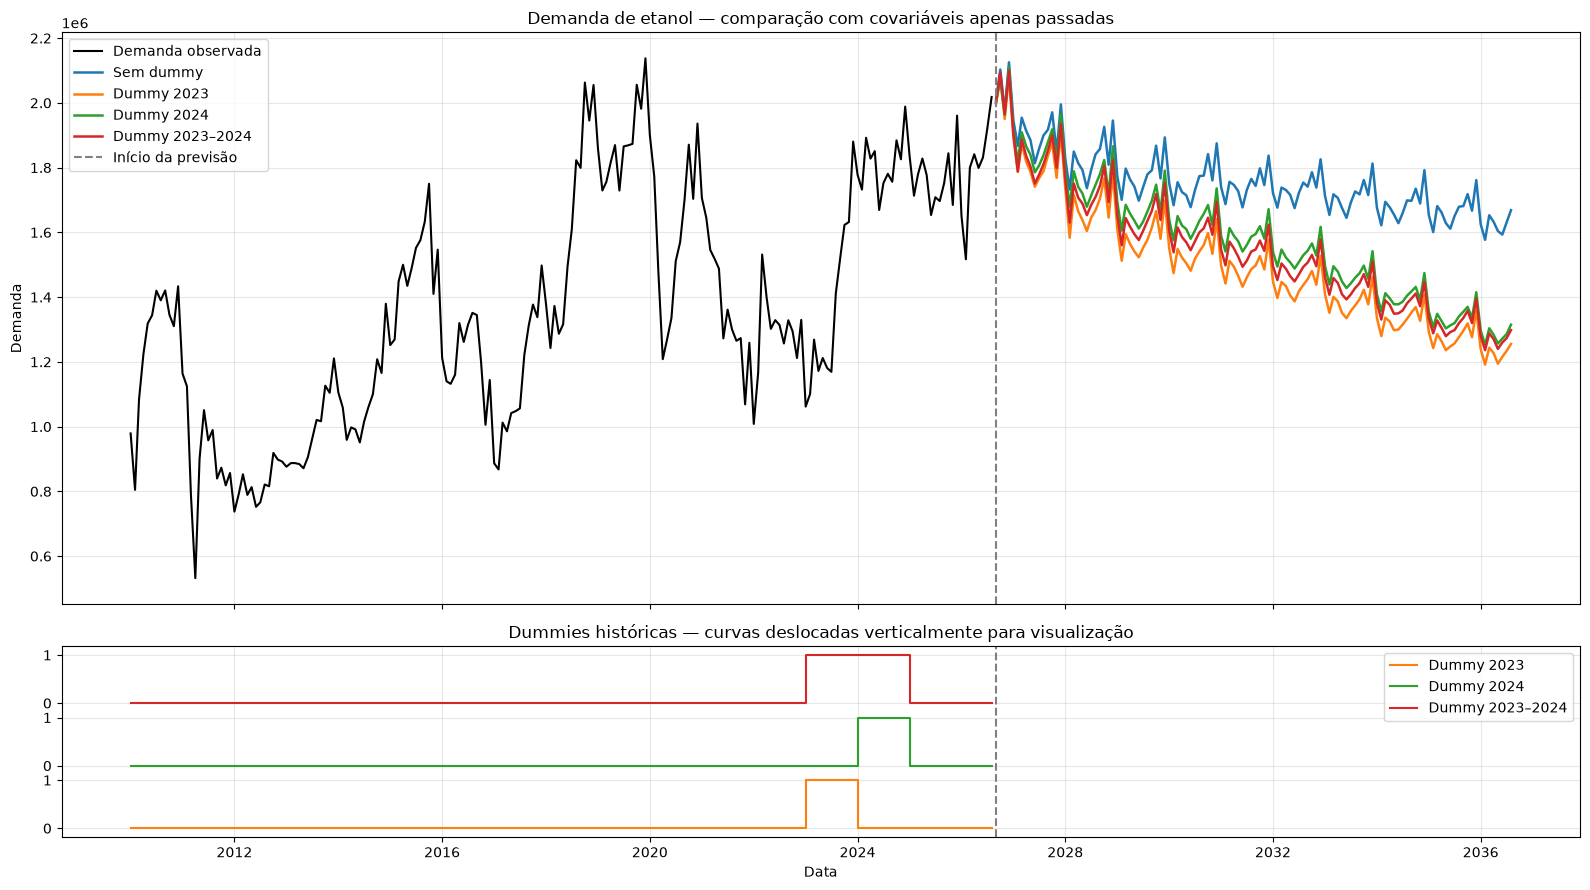

In [42]:
cores = {"Sem dummy": "tab:blue", "Dummy 2023": "tab:orange", "Dummy 2024": "tab:green", "Dummy 2023–2024": "tab:red"}

fig, axes = plt.subplots(2, 1, figsize=(16, 9), sharex=True, gridspec_kw={"height_ratios": [3, 1]})

axes[0].plot(datas_historicas, context, color="black", linewidth=1.5, label="Demanda observada")
for nome in cenarios:
    axes[0].plot(previsoes.index, previsoes[nome], color=cores[nome], linewidth=1.8, label=nome)

axes[0].axvline(forecast_dates[0], color="gray", linestyle="--", label="Início da previsão")
axes[0].set_title("Demanda de etanol — comparação com covariáveis apenas passadas")
axes[0].set_ylabel("Demanda")
axes[0].legend()
axes[0].grid(alpha=0.3)

for i, (nome, dummy) in enumerate(dummies.items()):
    axes[1].step(datas_historicas, dummy + i * 1.3, color=cores[nome], where="post", label=nome)

axes[1].axvline(forecast_dates[0], color="gray", linestyle="--")
axes[1].set_yticks([0, 1, 1.3, 2.3, 2.6, 3.6])
axes[1].set_yticklabels(["0", "1", "0", "1", "0", "1"])
axes[1].set_title("Dummies históricas — curvas deslocadas verticalmente para visualização")
axes[1].set_xlabel("Data")
axes[1].legend(loc="upper right")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()